# Wannier functions of silicon

Can we describe the bands of a crystal with a few orbitals sitting in the unit cell?
Bloch states are spread over the whole crystal, but at each k-point we may rotate them
among themselves. A good rotation, smooth in k, turns them into functions that are
localized in one cell. These are Wannier functions, and the most localized ones are
those that minimise the spread
$\Omega = \sum_n \left[\langle r^2\rangle_n - \langle \mathbf r\rangle_n^2\right]$
(Marzari and Vanderbilt).

Here we compute eight $sp^3$ functions of silicon from its twelve lowest bands. The
spread is $\Omega = 16.0532$ Å$^2$, the value of `pw2wannier90.x` and `wannier90.x` on
the same input to $4\times10^{-7}$ Å$^2$. Then we use the functions as a
tight-binding model and interpolate the bands. At the end the code chooses the
orbitals itself, from the atomic orbitals in the pseudopotential file.

In [1]:
import numpy as np
from defuqumat import Calculator

si = Calculator.from_keywords(
    lattice='fcc', a=5.3976, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
    pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo',
    ecut=272.1, kmesh=(8, 8, 8))
si.get_scf(conv_thr=1e-10)
windows = dict(num_bands=12, divisions=(4, 4, 4), dis_win=(None, 17.0), dis_froz=(None, 6.4),
               engine_options=dict(num_iter=200, conv_window=3))
w = si.get_wannier(8, ['Si:sp3'], **windows)
print(np.round(w.spreads_angstrom2, 4))
print({k: round(v, 4) for k, v in w.spread_terms_angstrom2().items()})

[1.8177 1.8177 1.8177 1.8177 2.1956 2.1956 2.1956 2.1956]
{'omega_i': 11.8135, 'omega_d': 0.1375, 'omega_od': 4.1022, 'omega_total': 16.0532}


Eight functions need eight bands, but the four lowest conduction bands of silicon
cross the bands above them. So we take twelve bands and choose the best
eight-dimensional subspace inside an outer window up to 17 eV. Every state below 6.4
eV, the valence band, is kept exactly: this is the frozen window. $\Omega_I$ is the part
of the spread that only depends on this subspace. The rotation lowers the other two
parts.

The two atoms give two groups of spreads, 1.8177 and 2.1955 Å$^2$, although they are
equivalent by symmetry. The trial lobes `Si:sp3` point along the four bonds of the
second atom, but away from the bonds of the atom at the origin. The minimisation is
local, so the two atoms end in different minima. If we turn the axes of the second
atom by 90 degrees about $z$, both start in the same way:

In [2]:
turned = ['f=0,0,0:sp3', 'f=0.25,0.25,0.25:sp3:z=0,0,1:x=0,1,0']
w = si.get_wannier(8, turned, **windows)
print(np.round(w.spreads_angstrom2, 4))
print({k: round(v, 4) for k, v in w.spread_terms_angstrom2().items()})
print('distance of each centre to its atom (A):',
      np.round(np.linalg.norm(w.centres_angstrom[:4], axis=1), 3))

[1.8046 1.8046 1.8046 1.8046 1.8046 1.8046 1.8046 1.8046]
{'omega_i': 11.8135, 'omega_d': 0.1043, 'omega_od': 2.5187, 'omega_total': 14.4365}
distance of each centre to its atom (A): [0.798 0.798 0.798 0.798]


Now the eight spreads are equal, and $\Omega$ is lower by 1.6 Å$^2$ with the same
$\Omega_I$. Each centre sits 0.80 Å from its atom.

The functions are a tight-binding model. `w.hoppings` is $H_{mn}(\mathbf R)$, the
hopping from function $m$ in the home cell to function $n$ in cell $\mathbf R$. Its
Fourier sum gives the bands at any k-point:

$$
H_{mn}(\mathbf k) = \sum_{\mathbf R} e^{i\mathbf k\cdot\mathbf R} H_{mn}(\mathbf R) .
$$

How fast do the hoppings decay? We take the largest one at each distance:

In [3]:
at = np.asarray(si.system.cell.at) * 0.529177
distance = np.linalg.norm(w.rvectors @ at, axis=1)
largest = np.abs(w.hoppings).max(axis=(1, 2)) * 13.6057
for d in np.unique(np.round(distance, 2))[:5]:
    print(f'|R| = {d:5.2f} A   max |H(R)| = {largest[np.isclose(np.round(distance, 2), d)].max():.3f} eV')

|R| =  0.00 A   max |H(R)| = 6.080 eV
|R| =  3.82 A   max |H(R)| = 1.571 eV
|R| =  5.40 A   max |H(R)| = 0.159 eV
|R| =  6.61 A   max |H(R)| = 0.204 eV
|R| =  7.63 A   max |H(R)| = 0.204 eV


The onsite block is 6.1 eV, the first shell of cells 1.6 eV and the second 0.16 eV.
Beyond that the hoppings stay at about 0.2 eV, so the model is not short-ranged
beyond the second shell. Hoppings beyond the 4x4x4 supercell are not in the model at all, and this is the
error a finer mesh removes. Let us now compare the interpolated
bands with the bands computed directly along a path, on the 4x4x4 mesh and on a 6x6x6
mesh.

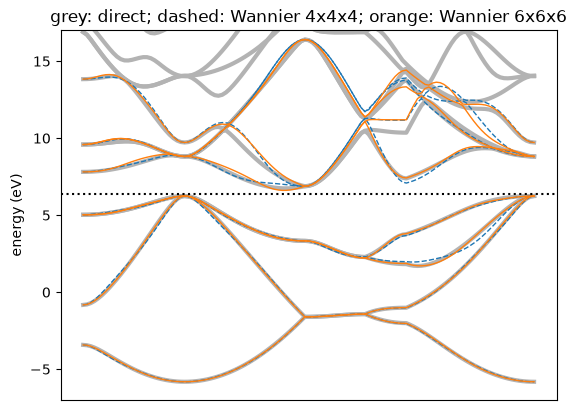

4x4x4 valence bands within 0.423 eV, at k = [-0.154  0.154  0.   ]


6x6x6 valence bands within 0.106 eV, at k = [-0.254  0.254  0.   ]


In [4]:
import matplotlib.pyplot as plt
path = si.kpath('L-G-X-W-K-G', 121)
crystal = np.asarray(si.system.cell.k_to_crystal(path.coords))
direct = np.asarray(si.get_bands(path, nbnd=12).eigenvalues) * 13.6057
fine = si.get_wannier(8, turned, **dict(windows, divisions=(6, 6, 6)))
x = np.arange(len(crystal))
plt.plot(x, direct, color='0.7', lw=3)
plt.plot(x, w.bands_ev(crystal), 'C0--', lw=1)
plt.plot(x, fine.bands_ev(crystal), 'C1-', lw=1)
plt.axhline(6.4, color='k', ls=':')
plt.ylim(-7, 17); plt.ylabel('energy (eV)'); plt.xticks([])
plt.title('grey: direct; dashed: Wannier 4x4x4; orange: Wannier 6x6x6')
plt.show()
for name, model in (('4x4x4', w), ('6x6x6', fine)):
    error = np.abs(model.bands_ev(crystal)[:, :4] - direct[:, :4]).max(axis=1)
    print(name, 'valence bands within %.3f eV, at k =' % error.max(), np.round(crystal[error.argmax()], 3))

Below the frozen window (dotted line) the interpolated bands follow the valence
bands. On this path the largest error is 0.42 eV on the 4x4x4 mesh and 0.11
eV on the 6x6x6 mesh.
Both are on the segment from K to $\Gamma$. The error falls with the mesh because the functions from a
finer mesh are sampled on a larger supercell. Above the window the model gives four
bands that follow the lowest conduction bands where these are not entangled with the
bands above.

| silicon, 12 bands to 8 $sp^3$ | $\Omega$ (Å$^2$), this code | $\Omega$ (Å$^2$), `wannier90.x` |
|---|---|---|
| norm-conserving | 16.053195 | 16.053195 |
| ultrasoft | 18.358071 | 18.358071 |
| PAW | 18.362773 | 18.362773 |

Can the code choose the trial orbitals itself? Every pseudopotential file carries the
orbitals of the free atom, here $3s$ and $3p$. So we use them on every atom, eight
orbitals for the two atoms. For each Bloch state we measure how much of it these
orbitals describe. This is the projectability:

$$
p_{m\mathbf k} = \sum_n |\langle \tilde g_n | S | \psi_{m\mathbf k}\rangle|^2 ,
$$

where $\tilde g_n$ are the orbitals after a Löwdin orthonormalisation. So $p = 1$ means
the state is made of these orbitals only, and $p = 0$ means it has nothing of them. A
state with $p \geq 0.95$ is kept exactly, a state with $p < 0.01$ is left out, and the
others go into the disentanglement. Every state up to 2 eV above the conduction band
minimum is also kept exactly. This is the method of Qiao, Pizzi and Marzari
(arXiv:2303.07877). We only call `get_wannier()` without orbitals:

In [5]:
auto = si.get_wannier(divisions=(4, 4, 4), engine_options=dict(num_iter=200, conv_window=3))
print(auto.num_wann, 'functions from', auto.num_bands, 'bands:', auto.projection_labels[:4], '...')
print('projectability at Gamma:', np.round(auto.projectability[0], 3))
print('kept exactly at each k-point:', auto.frozen.sum(axis=1).min(), 'to',
      auto.frozen.sum(axis=1).max(), '  left out in total:', (~auto.outer).sum())
print(np.round(auto.spreads_angstrom2, 4), round(auto.spread_terms_angstrom2()['omega_total'], 4))
error = np.abs(auto.bands_ev(crystal)[:, :4] - direct[:, :4]).max(axis=1)
print('4x4x4 valence bands within %.3f eV' % error.max())

8 functions from 16 bands: ('Si1 3S:s', 'Si1 3P:pz', 'Si1 3P:px', 'Si1 3P:py') ...
projectability at Gamma: [0.995 0.962 0.962 0.962 0.966 0.966 0.966 0.979 0.003 0.    0.    0.023
 0.023 0.023 0.01  0.014]
kept exactly at each k-point: 4 to 8   left out in total: 99
[1.4971 2.141  2.141  2.141  1.4971 2.141  2.141  2.141 ] 15.8399
4x4x4 valence bands within 0.359 eV


The eight functions are the $s$ and $p$ orbitals of the two atoms, and we did not
write a projection. At $\Gamma$ the four valence states have $p$ between 0.96 and
1.00. Most higher states have $p$ close to zero, and the one with $p = 0.003$ is left
out. The spread, 15.84 Å$^2$, lies between those of the two hybrid sets above, 16.05
and 14.44 Å$^2$. Along the path the valence bands are within 0.36 eV, against 0.42 eV
for the turned hybrids on the same 4x4x4 mesh.

| silicon, 12 bands to 8 $sp^3$ | $\Omega$ (Å$^2$), this code | $\Omega$ (Å$^2$), `wannier90.x` |
|---|---|---|
| norm-conserving | 16.053195 | 16.053195 |
| ultrasoft | 18.358071 | 18.358071 |
| PAW | 18.362773 | 18.362773 |

The `wannier90.x` column is `pw.x`, `pw2wannier90.x` and `wannier90.x` on the same
input, with the default `Si:sp3` orbitals. The projectabilities of the automatic set
are those of `pw2wannier90.x` with `atom_proj = .true.` to $10^{-6}$. The checks are in
`tests/unit/test_wannier.py`, `tests/unit/test_wannier_auto.py` and
`tests/regression/test_wannier.py`. The user guide has the theory on its page
"Wannier functions".